In [2]:
import sys
print(sys.executable)

/Users/souravrai/Documents/CodeAlpha_IrisClassification/.venv/bin/python


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'pandas'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df["species"] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
# Convert target numbers into actual species names
df["species"] = df["species"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

# Display the first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Get statistical summary of numerical columns
print("\nStatistical summary:")
df.describe()

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Number of duplicate rows: 1


In [8]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check the new dataset shape
print("Dataset shape after removing duplicates:", df.shape)

# Verify duplicates are removed
print("Number of duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (149, 5)
Number of duplicate rows: 0


In [9]:
# Count the number of samples in each species
species_counts = df["species"].value_counts()

print(species_counts)

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


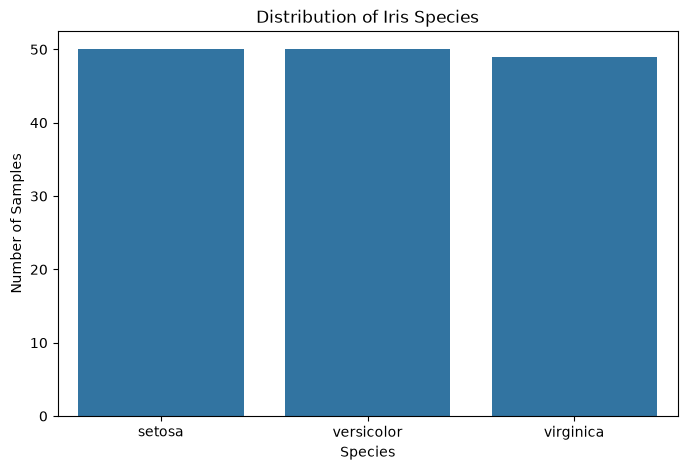

In [10]:
# Visualize the distribution of Iris species
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")

plt.show()

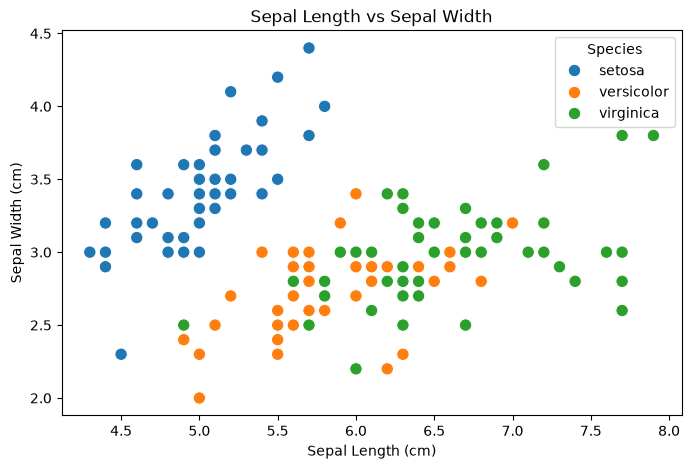

In [11]:
# Scatter plot: Sepal Length vs Sepal Width
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="sepal width (cm)",
    hue="species",
    s=80
)

plt.title("Sepal Length vs Sepal Width")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.legend(title="Species")
plt.show()

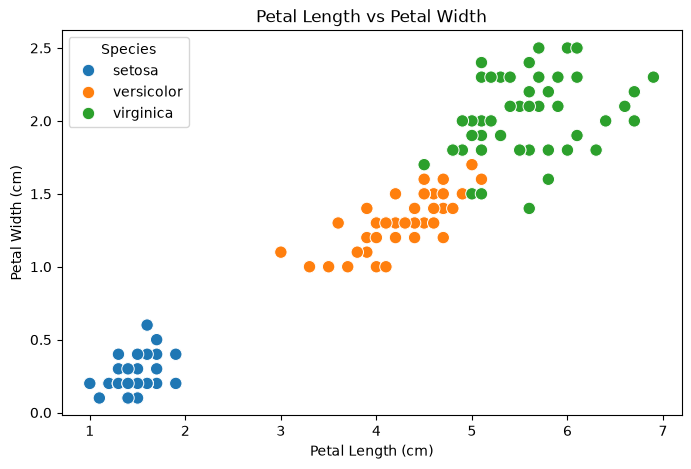

In [12]:
# Scatter plot: Petal Length vs Petal Width
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Species")
plt.show()

In [13]:
# Select only numerical features
features = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

# Calculate the correlation matrix
correlation_matrix = df[features].corr()

# Display the correlation matrix
print(correlation_matrix)

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.118129           0.873738   
sepal width (cm)           -0.118129          1.000000          -0.426028   
petal length (cm)           0.873738         -0.426028           1.000000   
petal width (cm)            0.820620         -0.362894           0.962772   

                   petal width (cm)  
sepal length (cm)          0.820620  
sepal width (cm)          -0.362894  
petal length (cm)          0.962772  
petal width (cm)           1.000000  


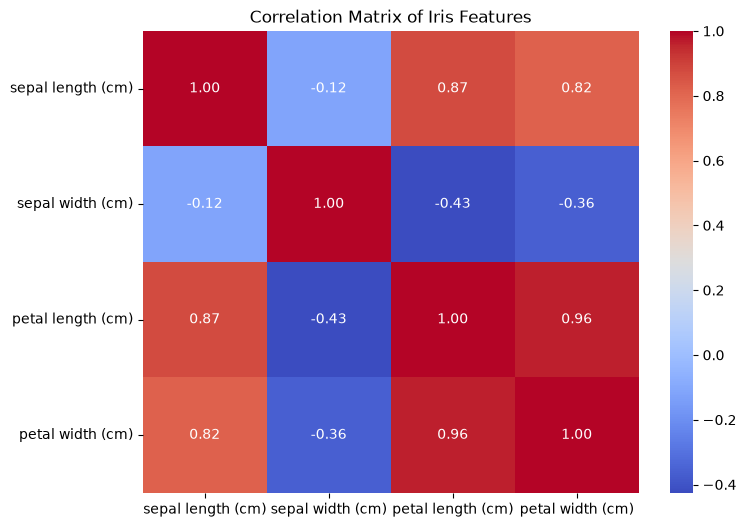

In [14]:
# Visualize the correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Iris Features")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

# Select input features
X = df[[
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]]

# Select target variable
y = df["species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 119
Testing samples: 30


In [16]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=200)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [17]:
# Make predictions on the test data
y_pred = model.predict(X_test)

# Display the first 10 predictions
print("Predicted species:")
print(y_pred[:10])

print("\nActual species:")
print(y_test.iloc[:10].values)

Predicted species:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']

Actual species:
<StringArray>
['versicolor', 'versicolor',  'virginica',     'setosa',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',  'virginica']
Length: 10, dtype: str


In [18]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 96.67%


In [19]:
from sklearn.metrics import classification_report

# Generate a detailed classification report
report = classification_report(y_test, y_pred)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



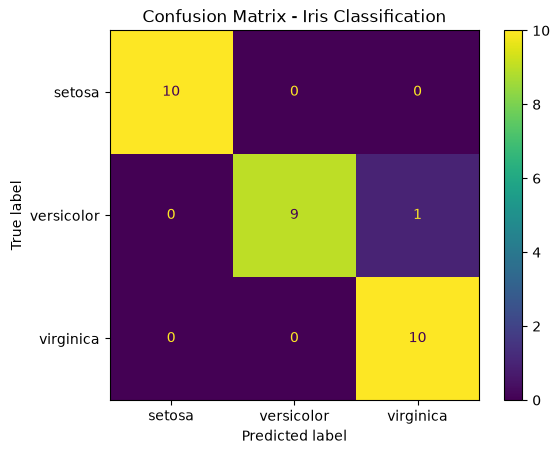

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.title("Confusion Matrix - Iris Classification")
plt.show()

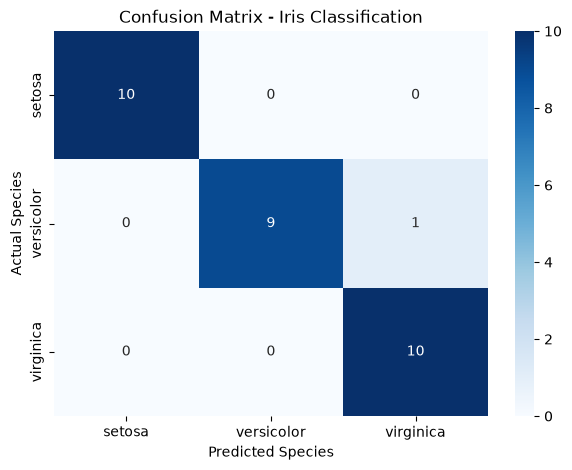

In [21]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Iris Classification")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

In [22]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [24]:
from sklearn.metrics import accuracy_score

# Calculate Decision Tree accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")

Decision Tree Accuracy: 93.33%


In [25]:
# Compare model performance
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy,
        dt_accuracy
    ]
})

# Convert accuracy to percentage
model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

model_comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.966667,96.67
1,Decision Tree,0.933333,93.33


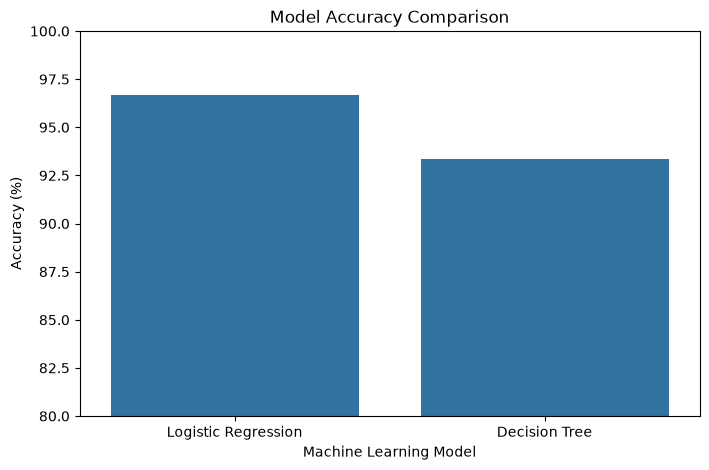

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(80, 100)

plt.show()

In [27]:
# Example flower measurements
sample_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict the species
prediction = model.predict(sample_flower)

print("Predicted species:", prediction[0])

Predicted species: setosa


/Users/souravrai/Documents/CodeAlpha_IrisClassification/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [28]:
# Function to predict Iris species
def predict_iris(sepal_length, sepal_width, petal_length, petal_width):
    sample = [[
        sepal_length,
        sepal_width,
        petal_length,
        petal_width
    ]]
    
    prediction = model.predict(sample)
    return prediction[0]


# Test the prediction function
result = predict_iris(5.1, 3.5, 1.4, 0.2)

print("Predicted Iris species:", result)

Predicted Iris species: setosa


/Users/souravrai/Documents/CodeAlpha_IrisClassification/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [29]:
# Final model results
print("Iris Flower Classification - Final Results")
print("-" * 45)
print(f"Logistic Regression Accuracy: {accuracy * 100:.2f}%")
print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")
print(f"Best Test Accuracy: {accuracy * 100:.2f}%")
print(f"Test Samples: {len(X_test)}")

Iris Flower Classification - Final Results
---------------------------------------------
Logistic Regression Accuracy: 96.67%
Decision Tree Accuracy: 93.33%
Best Test Accuracy: 96.67%
Test Samples: 30
